In [1]:
import pandas as pd
from rdkit import Chem
from rdkit.Chem import Descriptors, rdMolDescriptors


# 1. Descriptores moleculares

def compute_descriptors(mol):
    return {
        "MW": Descriptors.MolWt(mol),
        "LogP": Descriptors.MolLogP(mol),
        "TPSA": rdMolDescriptors.CalcTPSA(mol),
        "HBD": rdMolDescriptors.CalcNumHBD(mol),
        "HBA": rdMolDescriptors.CalcNumHBA(mol),
        "RotBonds": rdMolDescriptors.CalcNumRotatableBonds(mol)
    }


def score_molecule(mol):
    score = 0

    mw = Descriptors.MolWt(mol)
    logp = Descriptors.MolLogP(mol)
    tpsa = rdMolDescriptors.CalcTPSA(mol)
    hbd = rdMolDescriptors.CalcNumHBD(mol)
    hba = rdMolDescriptors.CalcNumHBA(mol)
    rot = rdMolDescriptors.CalcNumRotatableBonds(mol)

    # 🔹 Peso molecular
    if 250 <= mw <= 500:
        score += 2
    elif 500 < mw <= 650:
        score += 1
    else:
        score -= 1

    # 🔹 LogP
    if 1.5 <= logp <= 4:
        score += 2
    elif 4 < logp <= 5.5:
        score += 1
    elif logp > 5.5:
        score -= 1
    else:
        score -= 0.5

    # 🔹 TPSA
    if 20 <= tpsa <= 100:
        score += 2
    elif 100 < tpsa <= 140:
        score += 1
    else:
        score -= 1

    # 🔹 HBD
    if hbd <= 3:
        score += 1
    else:
        score -= 1

    # 🔹 HBA
    if 2 <= hba <= 8:
        score += 1
    else:
        score -= 1

    # 🔹 Flexibilidad
    if rot <= 8:
        score += 1
    elif rot <= 12:
        score += 0.5
    else:
        score -= 1

    return score



# 2. CARGAR DATOS

input_file = "samplingDHA1_ethers_final.csv"
df = pd.read_csv(input_file)

smiles_col = "SMILES"


# 3. PROCESAMIENTO

mols = []
desc_list = []
scores = []

for smi in df[smiles_col]:
    mol = Chem.MolFromSmiles(smi)

    if mol is None:
        mols.append(None)
        desc_list.append({})
        scores.append(None)
        continue

    mols.append(mol)

    desc = compute_descriptors(mol)
    desc_list.append(desc)

    s = score_molecule(mol)
    scores.append(s)

# 4. UNIR RESULTADOS

desc_df = pd.DataFrame(desc_list)

df = pd.concat([df, desc_df], axis=1)
df["Score"] = scores


# 5. FILTRADO FLEXIBLE

# Opción A: umbral
filtered_df = df[df["Score"] >= 4]

# Opción B: top N 
top_n = 50
top_df = df.sort_values(by="Score", ascending=False).head(top_n)


# 6. GUARDAR RESULTADOS

df.to_csv("DHA_all_scored.csv", index=False)
filtered_df.to_csv("DHA_filtered.csv", index=False)
top_df.to_csv("DHA_top50.csv", index=False)

print("Total moléculas:", len(df))
print("Filtradas (Score >= 4):", len(filtered_df))
print("Top seleccionadas:", len(top_df))

Total moléculas: 221
Filtradas (Score >= 4): 138
Top seleccionadas: 50


In [2]:
df1 = pd.read_csv("DHA_all_scored.csv")
df1.head()

,SMILES,SMILES_state,Scaffold,R-groups,NLL,class,ether_type,MW,LogP,TPSA,HBD,HBA,RotBonds,Score
0,COc1cc([N+](=O)[O-])c(OC)cc1COC1OC2OC3(C)CCC4C...,1,CC1CCC2C(C)C(O[*])OC3OC4(C)CCC1C32OO4,*Cc1c(OC)cc([N+]([O-])=O)c(OC)c1,13.74,ether,ALIPHATIC,479.526,4.33660,107.75,0,9,6,5.0
1,CC1CCC2C(C)C(Oc3ccn(-c4c(F)c(F)c(F)c(F)c4F)c(=...,1,CC1CCC2C(C)C(O[*])OC3OC4(C)CCC1C32OO4,n1(-c2c(F)c(F)c(F)c(F)c2F)c(=S)c(-c2ccc(OCc3cc...,37.60,ether,AROMATIC,741.775,9.73509,60.31,0,8,7,3.0
2,COc1cc(N)nc(NCCOC2OC3OC4(C)CCC5C(C)CCC(C2C)C35...,1,CC1CCC2C(C)C(O[*])OC3OC4(C)CCC1C32OO4,c1c(OC)nc(NCC*)nc1N,17.94,ether,ALIPHATIC,450.536,2.70390,119.21,2,10,6,6.0
3,CC1CCC2C(C)C(OCc3cc(F)c(F)c(F)c3F)OC3OC4(C)CCC...,1,CC1CCC2C(C)C(O[*])OC3OC4(C)CCC1C32OO4,c1c(F)c(F)c(F)c(F)c1C*,7.80,ether,ALIPHATIC,446.437,4.96760,46.15,0,5,3,8.0
4,CC1CCC2C(C)C(OCCn3cnc4ncnc(NCc5c(F)cc(F)c(F)c5...,1,CC1CCC2C(C)C(O[*])OC3OC4(C)CCC1C32OO4,c1c(F)c(F)c(F)c(CNc2ncnc3c2n(CC*)cn3)c1F,21.55,ether,ALIPHATIC,607.605,5.21940,101.78,1,10,7,4.0


In [ ]:
#dftop_df = pd.read_csv("DHA_top50.csv")
top_df.head()

,SMILES,SMILES_state,Scaffold,R-groups,NLL,class,ether_type,MW,LogP,TPSA,HBD,HBA,RotBonds,Score
12,CC1CCC2C(C)C(OCc3ccc(O)c(O)c3)OC3OC4(C)CCC1C32OO4,1,CC1CCC2C(C)C(O[*])OC3OC4(C)CCC1C32OO4,c1(O)c(O)ccc(C*)c1,10.10,ether,ALIPHATIC,406.475,3.8224,86.61,2,7,3,9.0
22,C#CCOC1OC2OC3(C)CCC4C(C)CCC(C1C)C24OO3,1,CC1CCC2C(C)C(O[*])OC3OC4(C)CCC1C32OO4,*CC#C,8.12,ether,ALIPHATIC,322.401,2.8442,46.15,0,5,2,9.0
16,COC1OC2OC3(C)CCC4C(C)CCC(C1C)C24OO3,1,CC1CCC2C(C)C(O[*])OC3OC4(C)CCC1C32OO4,C*,6.86,ether,ALIPHATIC,298.379,2.8408,46.15,0,5,1,9.0
43,CC1CCC2C(C)C(OCCCN3CCOCC3)OC3OC4(C)CCC1C32OO4,1,CC1CCC2C(C)C(O[*])OC3OC4(C)CCC1C32OO4,C(N1CCOCC1)CC*,12.40,ether,ALIPHATIC,411.539,2.9333,58.62,0,7,5,9.0
30,CCOC1OC2OC3(C)CCC4C(C)CCC(C1C)C24OO3,1,CC1CCC2C(C)C(O[*])OC3OC4(C)CCC1C32OO4,CC*,6.06,ether,ALIPHATIC,312.406,3.2309,46.15,0,5,2,9.0


In [4]:
if "ether_type" in filtered_df.columns and (filtered_df["ether_type"] == "AROMATIC").any():
    print("Hay éteres aromáticos")
else:
    print("No hay éteres aromáticos")

Hay éteres aromáticos


In [5]:
filtered_df[filtered_df["ether_type"]=="AROMATIC"]


,SMILES,SMILES_state,Scaffold,R-groups,NLL,class,ether_type,MW,LogP,TPSA,HBD,HBA,RotBonds,Score
56,CC1CCC2C(C)C(Oc3nc(NCC(=O)OC(C#N)C4C=CCCC4)ncc...,1,CC1CCC2C(C)C(O[*])OC3OC4(C)CCC1C32OO4,O=C(CNc1ncc(Br)c(*)n1)OC(C1CCCC=C1)C#N,41.41,ether,AROMATIC,633.54,5.02948,134.05,1,11,7,4.0


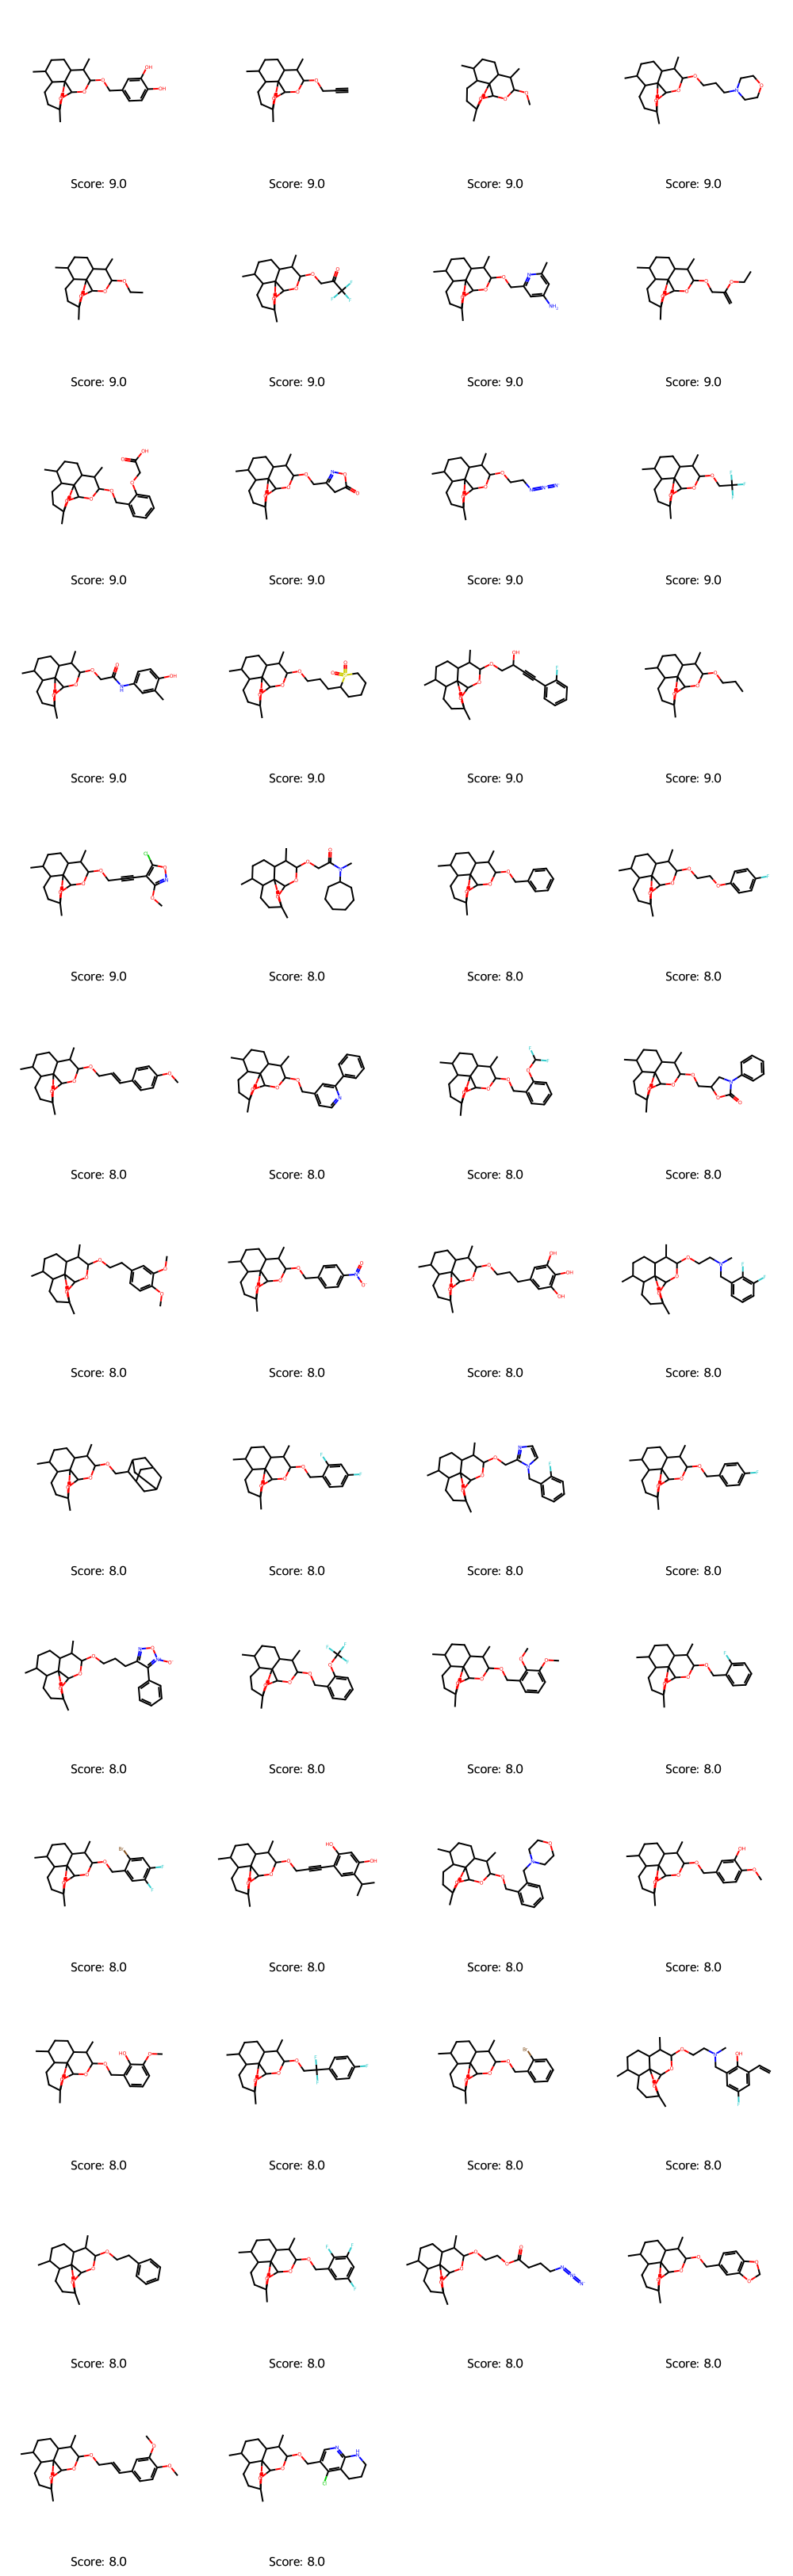

In [6]:
from rdkit.Chem import Draw

subset = top_df

mols = []
legends = []

for idx, row in subset.iterrows():
    mol = Chem.MolFromSmiles(row["SMILES"])
    if mol:
        mols.append(mol)
        legends.append(f"Score: {row['Score']:.1f}")

# Dibujar grid
img = Draw.MolsToGridImage(
    mols,
    molsPerRow=4,
    subImgSize=(250, 250),
    legends=legends
)

img